# Elaborato di Apprendimento Automatico e Apprendimento Profondo

**Studente:** Leo Messner, Matr. 0322600155

**Dataset:** Breast Cancer Wisconsin (Diagnostic), UCI Machine Learning Repository (id 17)

Obiettivo: classificare i tumori al seno come benigni (B) o maligni (M) a partire da 30 feature numeriche
calcolate da immagini digitalizzate di agoaspirati (FNA).

Task svolti: analisi delle feature con PCA, cinque algoritmi di classificazione, metriche di valutazione,
matrici di confusione e curve ROC, spiegabilità con SHAP (opzione b).

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap
from ucimlrepo import fetch_ucirepo

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay)

SEED = 42
np.random.seed(SEED)
%config InlineBackend.figure_format = 'retina'

## 1. Caricamento del dataset

In [2]:
# download dal repository UCI (id 17 = Breast Cancer Wisconsin Diagnostic)
bcw = fetch_ucirepo(id=17)
X = bcw.data.features
y_raw = bcw.data.targets["Diagnosis"]

print("Istanze:", X.shape[0], " Feature:", X.shape[1])
print("Valori mancanti:", X.isna().sum().sum())
print(y_raw.value_counts())
X.head()

Istanze: 569  Feature: 30
Valori mancanti: 0
Diagnosis
B    357
M    212
Name: count, dtype: int64


,radius1,texture1,perimeter1,area1,smoothness1,compactness1,concavity1,concave_points1,symmetry1,fractal_dimension1,...,radius3,texture3,perimeter3,area3,smoothness3,compactness3,concavity3,concave_points3,symmetry3,fractal_dimension3
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


Le 30 feature descrivono 10 caratteristiche del nucleo cellulare (radius, texture, perimeter, area, smoothness,
compactness, concavity, concave points, symmetry, fractal dimension), ognuna in tre versioni: media
(suffisso 1), errore standard (suffisso 2) e valore peggiore (suffisso 3). La classe positiva è M (maligno),
codificata con 1.

In [3]:
y = (y_raw == "M").astype(int).values   # 1 = maligno, 0 = benigno

## 2. Suddivisione in training, validation e test

Uso una sola suddivisione stratificata 60/20/20 per tutti gli esperimenti: il training set serve per
addestrare i modelli, il validation set per scegliere gli iperparametri e il test set solo per la valutazione
finale. Lo StandardScaler è stimato solo sul training set.

In [4]:
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.4, stratify=y, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, stratify=y_temp, random_state=SEED)

scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_val_s = scaler.transform(X_val)
X_test_s = scaler.transform(X_test)

print("Training:", X_train.shape[0], " Validation:", X_val.shape[0], " Test:", X_test.shape[0])

Training: 341  Validation: 114  Test: 114


## 3. Analisi delle feature con PCA

La PCA è calcolata su tutte le 30 feature standardizzate del training set. La standardizzazione è necessaria
perché le feature hanno scale molto diverse (per esempio area e smoothness).

Varianza spiegata PC1: 0.430, PC2: 0.200
Componenti necessarie per il 95% della varianza: 10


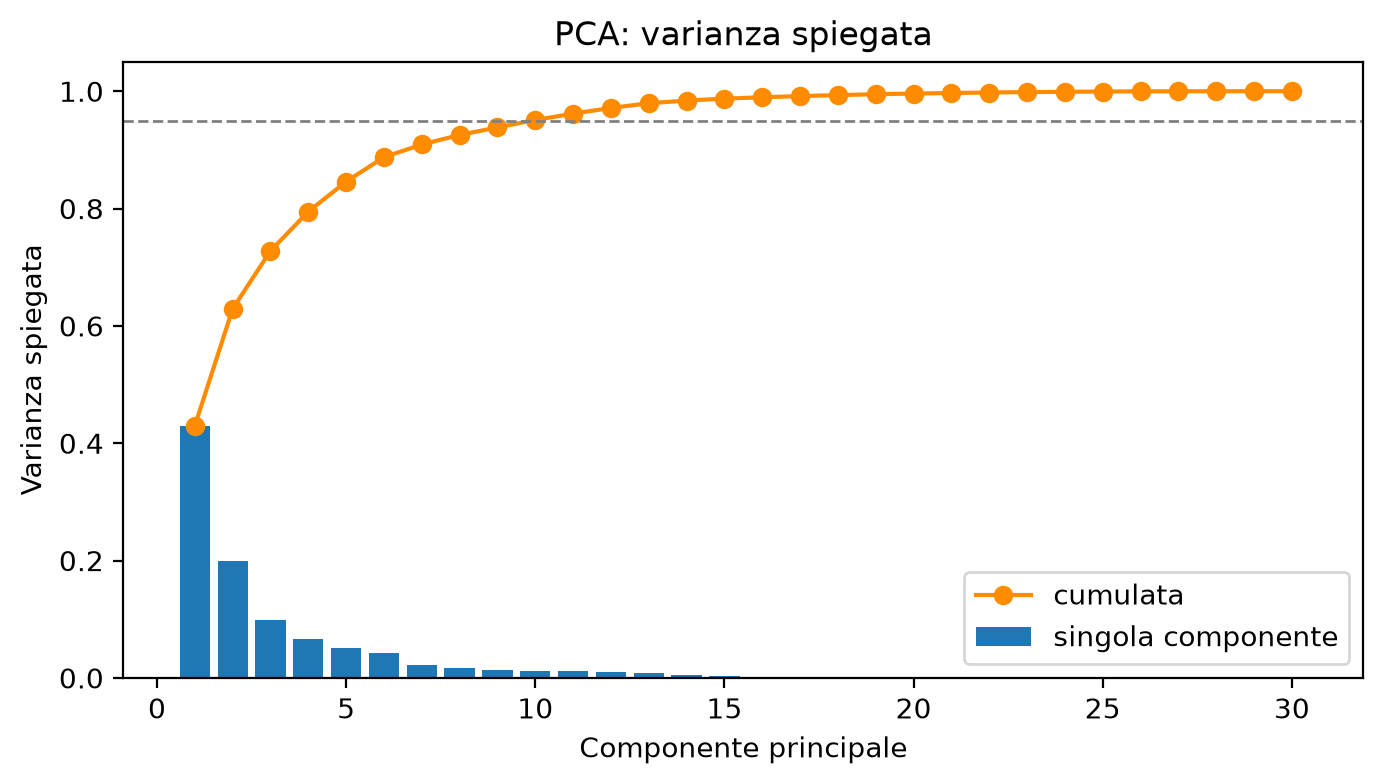

In [5]:
pca = PCA().fit(X_train_s)
var = pca.explained_variance_ratio_
cum = np.cumsum(var)

print("Varianza spiegata PC1: %.3f, PC2: %.3f" % (var[0], var[1]))
print("Componenti necessarie per il 95% della varianza:", np.argmax(cum >= 0.95) + 1)

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(range(1, 31), var, label="singola componente")
ax.plot(range(1, 31), cum, "o-", color="darkorange", label="cumulata")
ax.axhline(0.95, color="gray", linestyle="--", linewidth=1)
ax.set_xlabel("Componente principale")
ax.set_ylabel("Varianza spiegata")
ax.set_title("PCA: varianza spiegata")
ax.legend()
plt.show()

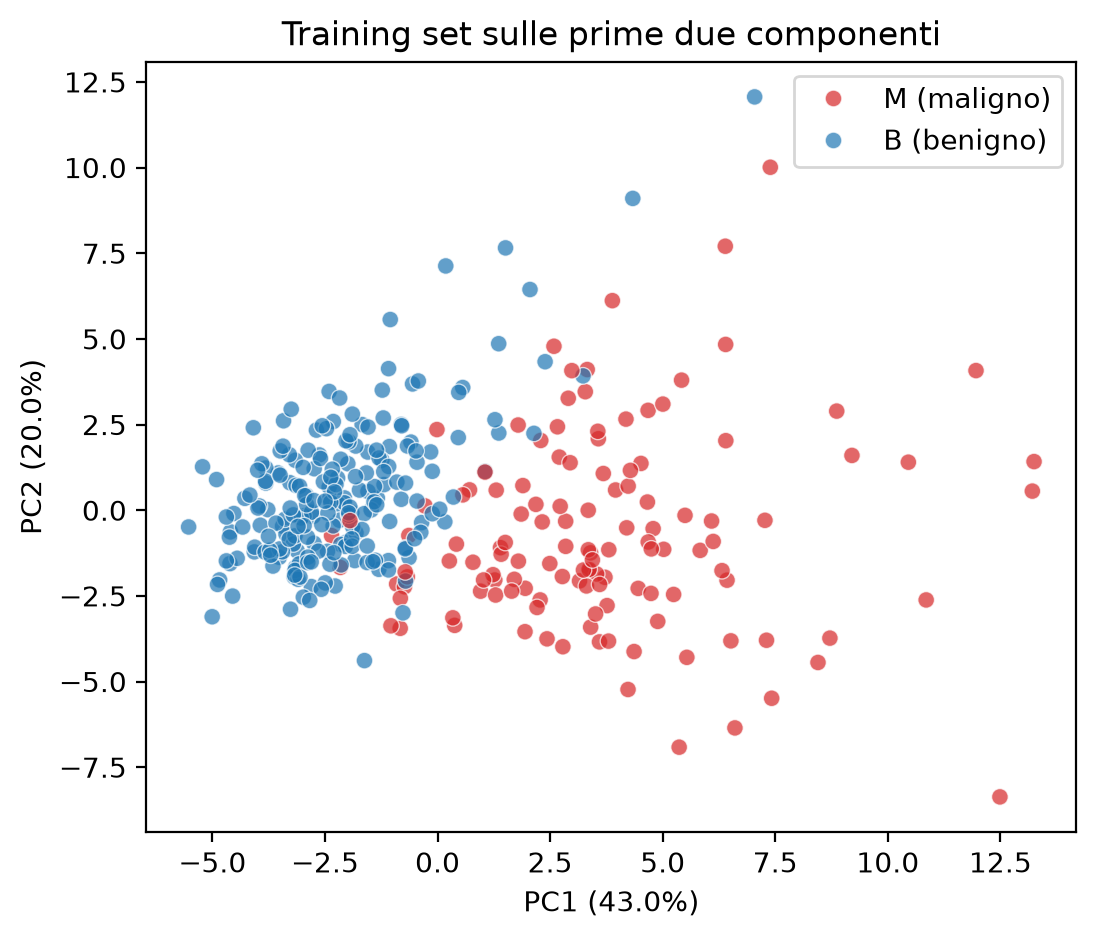

In [6]:
Z = pca.transform(X_train_s)[:, :2]
classe = np.where(y_train == 1, "M (maligno)", "B (benigno)")

plt.figure(figsize=(6, 5))
sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=classe, alpha=0.7,
                palette={"B (benigno)": "tab:blue", "M (maligno)": "tab:red"})
plt.xlabel("PC1 (%.1f%%)" % (100 * var[0]))
plt.ylabel("PC2 (%.1f%%)" % (100 * var[1]))
plt.title("Training set sulle prime due componenti")
plt.show()

In [7]:
loadings = pd.DataFrame(pca.components_[:2].T, index=X.columns, columns=["PC1", "PC2"])
print("Feature con peso maggiore su PC1:")
print(loadings["PC1"].abs().sort_values(ascending=False).head(5).round(3))
print("\nFeature con peso maggiore su PC2:")
print(loadings["PC2"].abs().sort_values(ascending=False).head(5).round(3))

Feature con peso maggiore su PC1:
concave_points1    0.265
concavity1         0.260
concave_points3    0.252
compactness1       0.243
perimeter3         0.233
Name: PC1, dtype: float64

Feature con peso maggiore su PC2:
fractal_dimension1    0.355
fractal_dimension3    0.278
fractal_dimension2    0.267
radius1               0.245
area1                 0.242
Name: PC2, dtype: float64


**Commento.** Le prime due componenti spiegano il 63% della varianza (PC1 43,0%, PC2 20,0%) e servono
10 componenti per arrivare al 95%: molte feature sono correlate tra loro (per esempio raggio, perimetro e
area misurano quasi la stessa cosa). Nel grafico le due classi sono già abbastanza separate lungo PC1: i
tumori maligni hanno valori di PC1 più alti. PC1 è legata soprattutto a concavità, punti concavi e
compattezza, cioè alla forma irregolare del nucleo; PC2 soprattutto alla dimensione frattale e, in misura
minore, a raggio e area. Questo fa pensare che anche classificatori semplici possano funzionare bene.

## 4. Classificatori e scelta degli iperparametri

Uso cinque algoritmi visti nel corso: Naive Bayes, KNN, SVM, Decision Tree e Random Forest. Per ogni
algoritmo provo pochi valori dell'iperparametro principale e tengo quello con l'F1 migliore sul validation
set (in caso di parità resta il primo valore della lista). Naive Bayes non ha iperparametri da scegliere.

Per la curva ROC serve un punteggio continuo: uso la probabilità della classe M (`predict_proba`) e, per la
SVM, la distanza dall'iperpiano (`decision_function`).

In [8]:
def punteggio(m, dati):
    # punteggio continuo per la classe M (serve per ROC AUC e SHAP)
    if isinstance(m, SVC):
        return m.decision_function(dati)
    return m.predict_proba(dati)[:, 1]

In [9]:
candidati = {
    "Naive Bayes":   [GaussianNB()],
    "KNN":           [KNeighborsClassifier(n_neighbors=k) for k in [1, 3, 5, 7, 9, 11, 15]],
    "SVM":           [SVC(kernel="rbf", C=c) for c in [0.1, 1, 10, 100]],
    "Decision Tree": [DecisionTreeClassifier(max_depth=d, random_state=SEED) for d in [2, 3, 4, 5, 6, None]],
    "Random Forest": [RandomForestClassifier(n_estimators=n, random_state=SEED) for n in [50, 100, 200]],
}
parametro = {"Naive Bayes": None, "KNN": "n_neighbors", "SVM": "C",
             "Decision Tree": "max_depth", "Random Forest": "n_estimators"}

modelli = {}
righe = []
for nome, lista in candidati.items():
    migliore, f1_migliore = None, -1
    p = parametro[nome]
    for m in lista:
        m.fit(X_train_s, y_train)
        f1_val = f1_score(y_val, m.predict(X_val_s))
        if p is not None:
            print("%-14s %s = %-5s F1 validation = %.4f" % (nome, p, m.get_params()[p], f1_val))
        if f1_val > f1_migliore:
            migliore, f1_migliore = m, f1_val
    modelli[nome] = migliore
    scelta = "-" if p is None else "%s = %s" % (p, migliore.get_params()[p])
    righe.append([nome, scelta, round(f1_migliore, 4)])

pd.DataFrame(righe, columns=["Modello", "Iperparametro scelto", "F1 validation"])

KNN            n_neighbors = 1     F1 validation = 0.9398
KNN            n_neighbors = 3     F1 validation = 0.9383
KNN            n_neighbors = 5     F1 validation = 0.9383
KNN            n_neighbors = 7     F1 validation = 0.9250
KNN            n_neighbors = 9     F1 validation = 0.9114
KNN            n_neighbors = 11    F1 validation = 0.9250
KNN            n_neighbors = 15    F1 validation = 0.9250


SVM            C = 0.1   F1 validation = 0.9136
SVM            C = 1     F1 validation = 0.9250
SVM            C = 10    F1 validation = 0.9639
SVM            C = 100   F1 validation = 0.9535
Decision Tree  max_depth = 2     F1 validation = 0.9048
Decision Tree  max_depth = 3     F1 validation = 0.9136
Decision Tree  max_depth = 4     F1 validation = 0.8810
Decision Tree  max_depth = 5     F1 validation = 0.9268
Decision Tree  max_depth = 6     F1 validation = 0.8916
Decision Tree  max_depth = None  F1 validation = 0.9157


Random Forest  n_estimators = 50    F1 validation = 0.9398


Random Forest  n_estimators = 100   F1 validation = 0.9398


Random Forest  n_estimators = 200   F1 validation = 0.9398


,Modello,Iperparametro scelto,F1 validation
0,Naive Bayes,-,0.9024
1,KNN,n_neighbors = 1,0.9398
2,SVM,C = 10,0.9639
3,Decision Tree,max_depth = 5,0.9268
4,Random Forest,n_estimators = 50,0.9398


**Commento.** Per il KNN vince k = 1, ma con un solo caso di differenza rispetto a k = 3 e k = 5: il
validation set ha solo 114 esempi, quindi differenze così piccole non sono molto affidabili. Per la SVM il
valore migliore è C = 10, per l'albero max_depth = 5. Per la Random Forest il numero di alberi non cambia il
risultato, quindi resta il primo valore (50 alberi).

## 5. Valutazione sul test set

In [10]:
risultati = []
prob_test = {}
for nome, m in modelli.items():
    pred = m.predict(X_test_s)
    prob = punteggio(m, X_test_s)
    prob_test[nome] = prob
    risultati.append({
        "Modello": nome,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC AUC": roc_auc_score(y_test, prob),
    })

tabella = pd.DataFrame(risultati).set_index("Modello").round(4)
tabella

,Accuracy,Precision,Recall,F1,ROC AUC
Modello,,,,,
Naive Bayes,0.9298,0.9250,0.8810,0.9024,0.9914
KNN,0.9211,0.9024,0.8810,0.8916,0.9127
SVM,0.9825,1.0000,0.9524,0.9756,0.9947
Decision Tree,0.9386,0.9487,0.8810,0.9136,0.9259
Random Forest,0.9825,1.0000,0.9524,0.9756,0.9939


## 6. Matrici di confusione e curve ROC

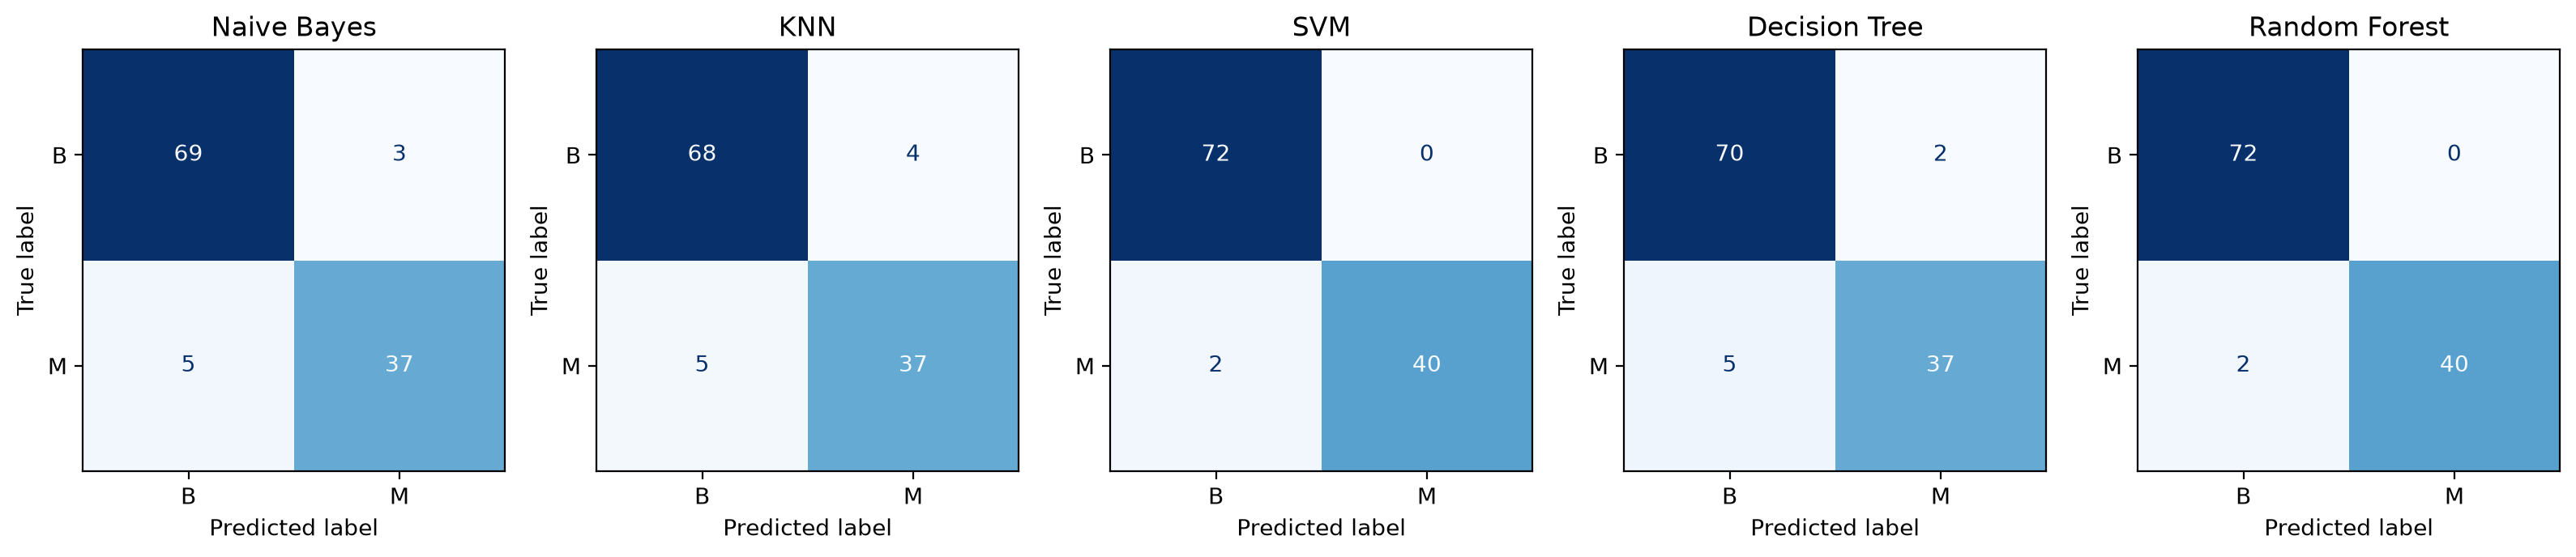

In [11]:
fig, axes = plt.subplots(1, 5, figsize=(16, 3.4))
for ax, (nome, m) in zip(axes, modelli.items()):
    cm = confusion_matrix(y_test, m.predict(X_test_s))
    ConfusionMatrixDisplay(cm, display_labels=["B", "M"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(nome)
plt.tight_layout()
plt.show()

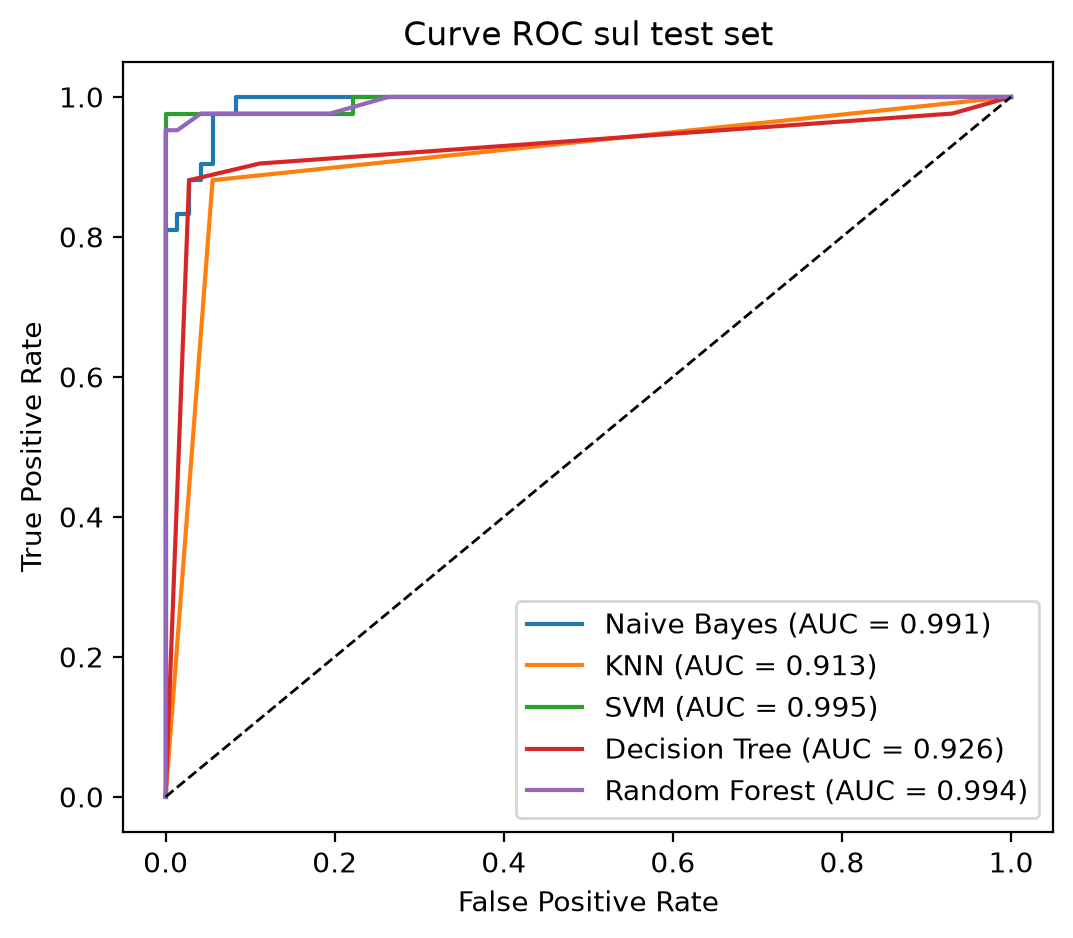

In [12]:
plt.figure(figsize=(6, 5))
for nome, prob in prob_test.items():
    fpr, tpr, _ = roc_curve(y_test, prob)
    plt.plot(fpr, tpr, label="%s (AUC = %.3f)" % (nome, roc_auc_score(y_test, prob)))
plt.plot([0, 1], [0, 1], "k--", linewidth=1)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Curve ROC sul test set")
plt.legend(loc="lower right")
plt.show()

**Commento.** SVM e Random Forest ottengono i risultati migliori sul test set: accuracy 0,9825, precision
1,0 e recall 0,9524, cioè nessun falso positivo e solo 2 tumori maligni su 42 classificati come benigni.
Gli altri tre modelli sbagliano 5 tumori maligni. In ambito medico il falso negativo è l'errore più grave,
quindi la recall è la metrica più importante. Naive Bayes ha un F1 più basso ma una ROC AUC alta (0,991):
ordina bene i casi, ma con la soglia standard sbaglia di più. KNN con k = 1 e il Decision Tree danno solo
pochi valori di punteggio diversi, per questo la loro curva ROC ha pochi punti e l'AUC è più bassa
(0,913 e 0,926).

## 7. Spiegabilità con SHAP (opzione b)

Applico SHAP al modello con l'F1 migliore sul validation set. Uso un explainer model-agnostic (permutation)
con 100 esempi del training set come background. Il valore SHAP di una feature indica di quanto quella
feature sposta il punteggio del modello verso M (valori positivi) o verso B (valori negativi).

In [13]:
nome_best = max(righe, key=lambda r: r[2])[0]
best = modelli[nome_best]
print("Modello spiegato con SHAP:", nome_best)

X_train_df = pd.DataFrame(X_train_s, columns=X.columns)
X_test_df = pd.DataFrame(X_test_s, columns=X.columns)

f = lambda dati: punteggio(best, dati)
explainer = shap.Explainer(f, shap.maskers.Independent(X_train_df, max_samples=100), seed=SEED)
sv = explainer(X_test_df, silent=True)
sv.data = X_test.values   # nei grafici mostro i valori originali, non standardizzati

Modello spiegato con SHAP: SVM


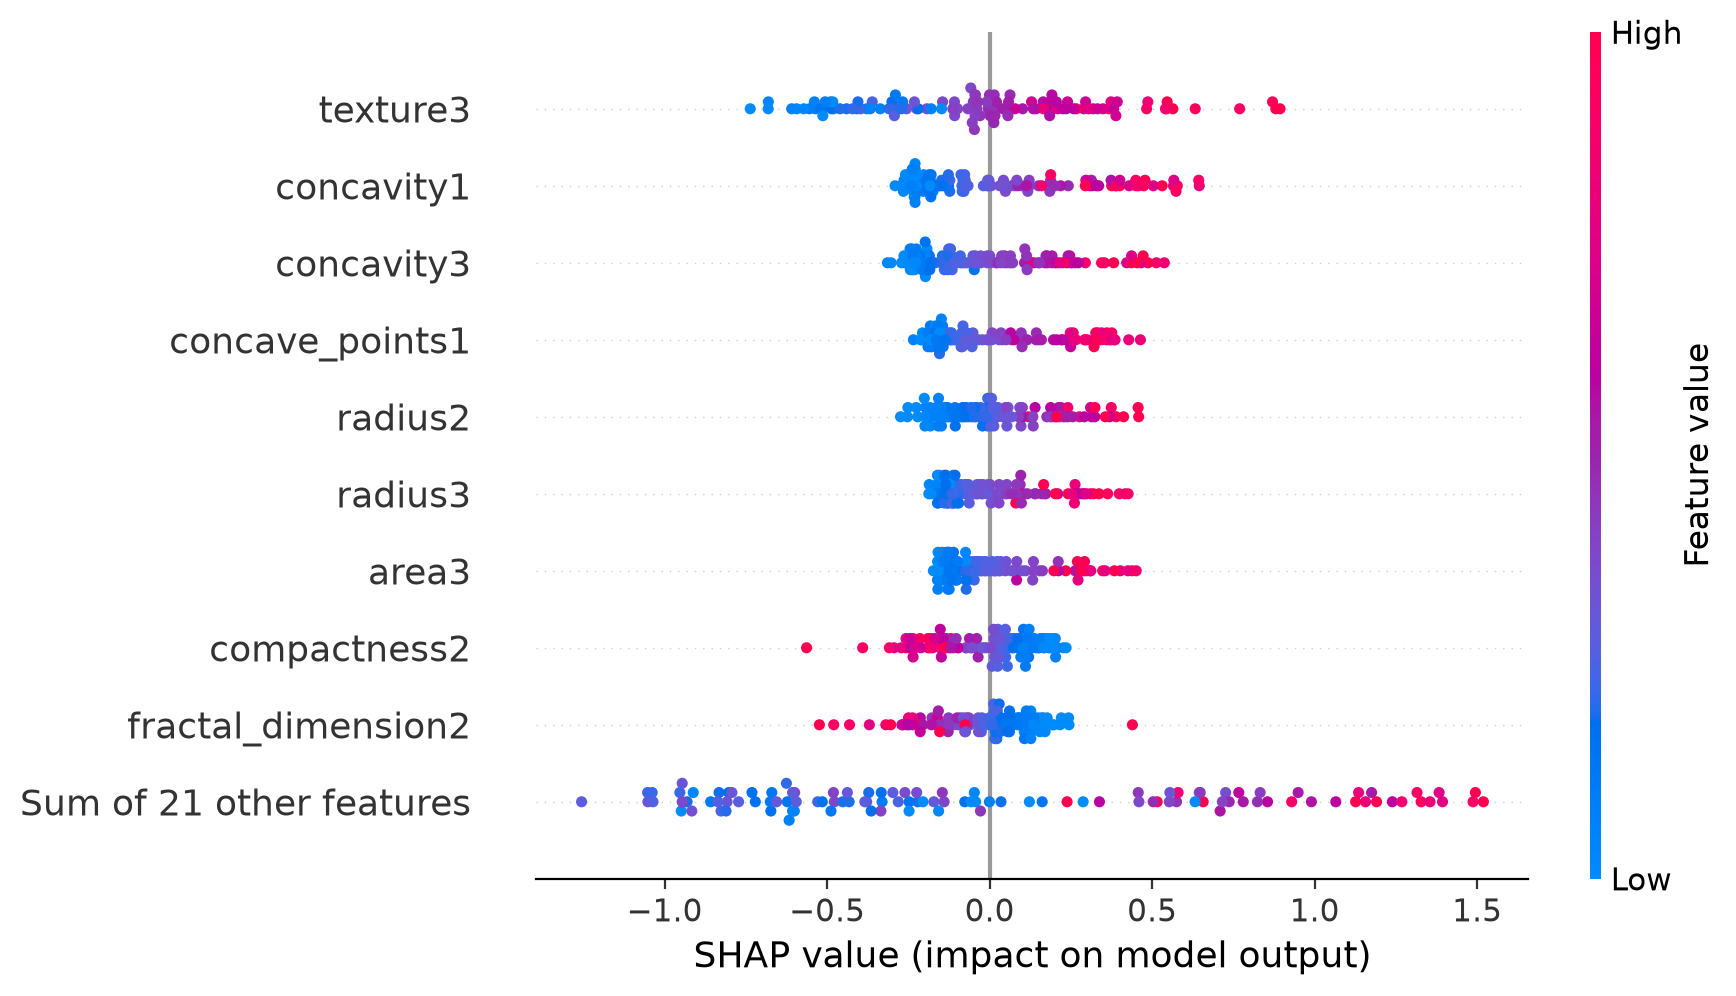

In [14]:
shap.plots.beeswarm(sv, max_display=10)

Caso 9 del test set, classe reale M, punteggio del modello: 1.80


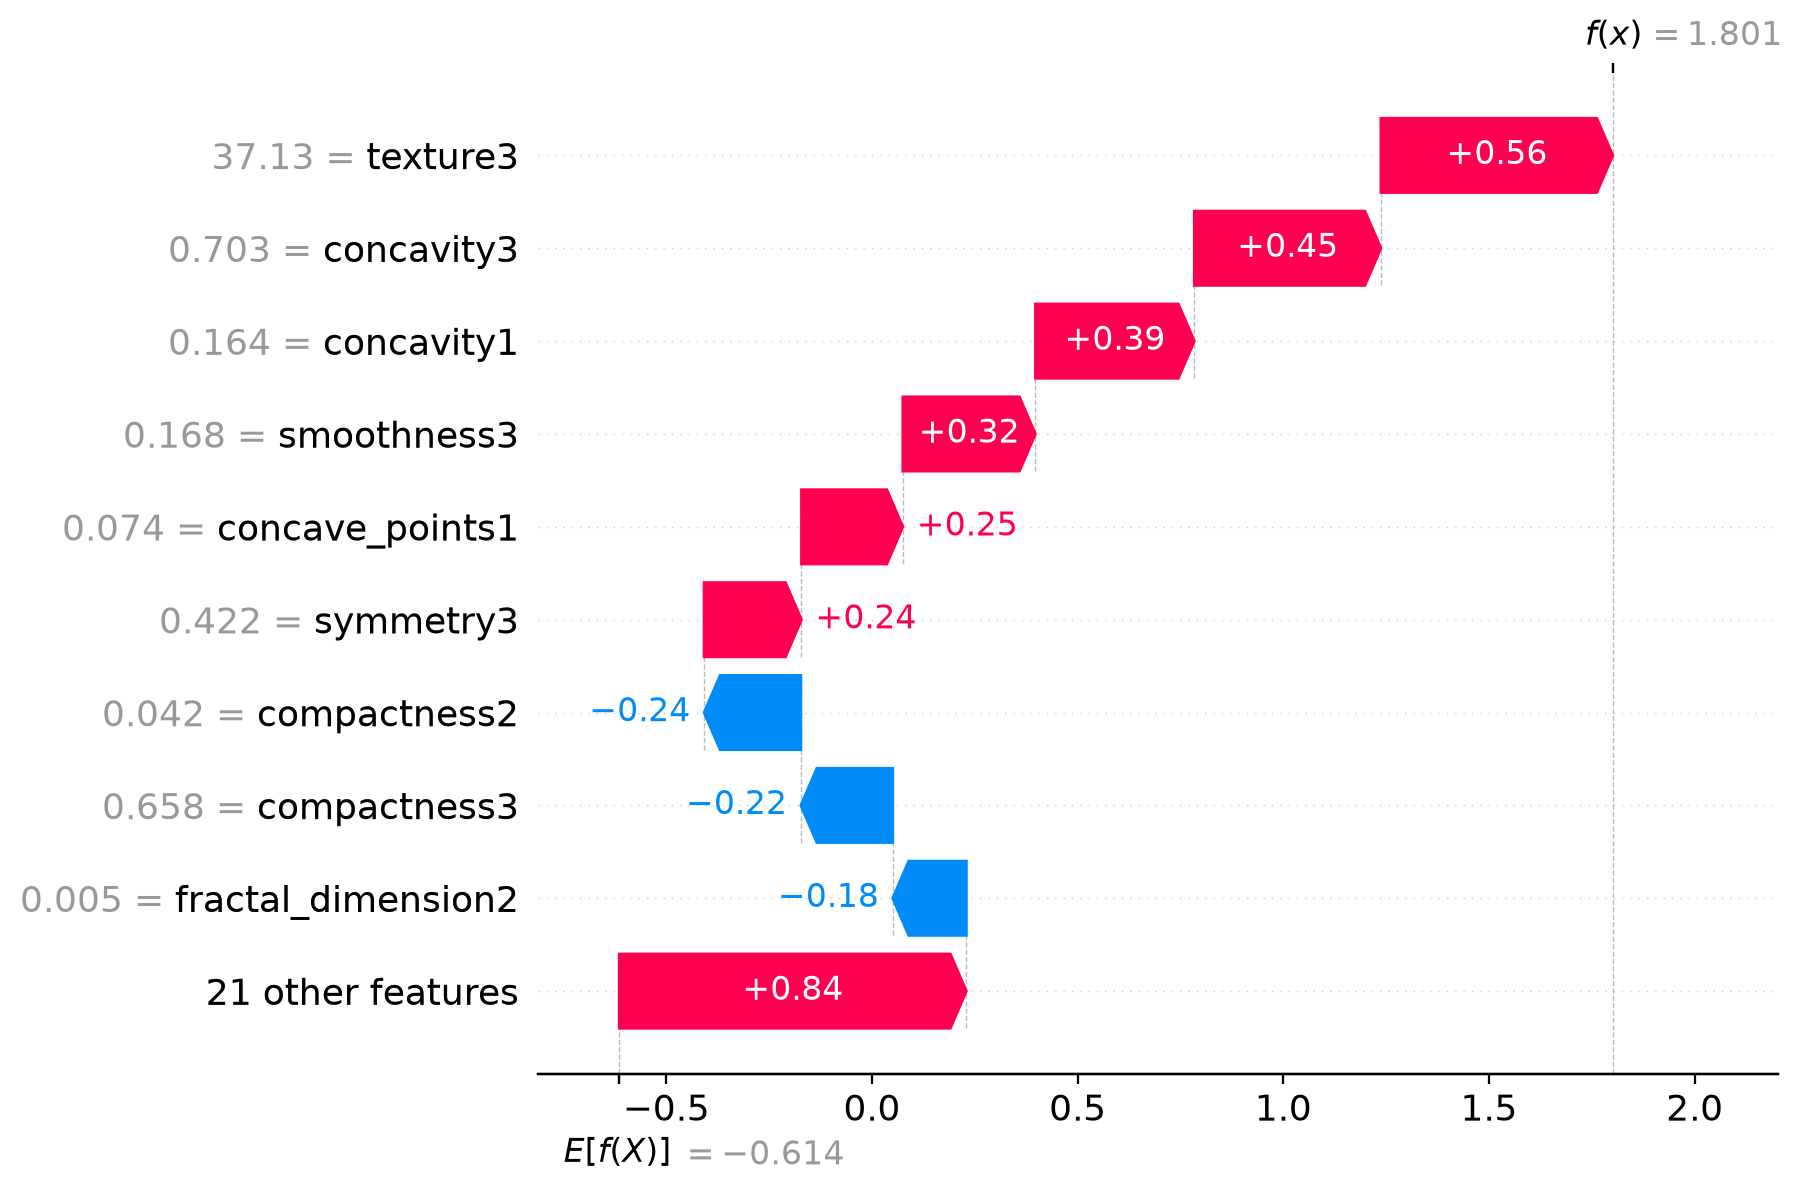

In [15]:
# spiegazione di un singolo caso maligno del test set
i = int(np.where(y_test == 1)[0][0])
print("Caso %d del test set, classe reale M, punteggio del modello: %.2f" % (i, f(X_test_s[i:i + 1])[0]))
shap.plots.waterfall(sv[i], max_display=10)

**Commento.** Il modello spiegato è la SVM (C = 10), che ha l'F1 migliore sul validation set. Le feature più
importanti sono texture3 (texture peggiore), concavity1, concavity3, concave_points1 e alcune misure di
dimensione (radius2, radius3, area3): valori alti spingono verso M. Per compactness2 e fractal_dimension2
succede il contrario: valori alti spingono verso B. Questo è coerente con la PCA, dove concavità e punti
concavi pesano molto su PC1. La riga "Sum of 21 other features" è grande perché molte feature sono
correlate e l'informazione è distribuita su tutte. Nel caso singolo (un tumore maligno del test set) il
punteggio passa dal valore medio −0,61 a 1,80, soprattutto per texture3, concavity3 e concavity1.

Un limite: l'explainer tratta le feature come indipendenti, mentre qui sono molto correlate, quindi il
valore SHAP della singola feature va letto con cautela.

## 8. Conclusioni

Tutti e cinque i classificatori superano il 92% di accuracy sul test set. SVM e Random Forest sono i
migliori (accuracy 98,2%, F1 0,976, ROC AUC 0,99) e sbagliano solo 2 tumori maligni su 42. La PCA mostra
che le classi sono già ben separate sulla prima componente, e SHAP conferma che le feature più utili sono
quelle legate alla forma irregolare del nucleo (concavità, punti concavi, texture) e alla sua dimensione.
Il test set ha solo 114 casi, quindi un caso in più o in meno cambia l'accuracy di quasi un punto: per un
confronto più stabile si potrebbe usare la k-fold cross validation.